# Load libraries

In [70]:
import h5py
import pandas as pd
import numpy as np
import torch
import math
import matplotlib.pyplot as plt

In [71]:
def get_unique_couplings(data):
    unique_elements = set(data)
    unique_elements_list = sorted(unique_elements)
    final_list = [round(float(elem), 1) for elem in unique_elements_list]
    print(final_list)
    return final_list

def compare_distributions(variable, weights, indices_dictionary, x_range=[0,100], variable_name='',n_bins=40):

        plt.figure(figsize=(10, 6),dpi=100)


        for coupling, indices in indices_dictionary.items():
            #if coupling!=600:
            #    continue
            data = variable[indices]
            if variable_name=='W':
                plt.hist(data, bins=n_bins, histtype='step', label=f'Coupling {coupling}', density=False, range=x_range)
            else:
                plt.hist(data, weights=weights[indices], bins=n_bins, histtype='step', label=f'Coupling {coupling}', density=True, range=x_range)

        plt.xlabel(variable_name)
        plt.xlim(x_range[0],x_range[1])
        plt.ylabel('Density')
        plt.title(f'Distribution of {variable_name}')
        plt.legend()
        # plt.yscale('log')
        plt.show()

# Read the inputs.

In [72]:
from numpy.lib import recfunctions as rfn

data_file = h5py.File('../../H5Files/Coupling_Inference_negW.h5')
labels_dataset = data_file['LABELS']['CLASS']
signal_indices = np.argwhere(labels_dataset[:] == 1)
background_indices = np.argwhere(labels_dataset[:] == 0)
print('BG events = ',len(background_indices))
print('Signal events = ',len(signal_indices))

couplings_array = data_file['INPUTS']['EVENT_GLOBAL']['coupling'][:]
coupling_values = get_unique_couplings(couplings_array)
indices_per_coupling = {}
for coupling in coupling_values:
    indices = np.argwhere(abs(couplings_array[:] - coupling) < 1e-3)
    indices_per_coupling[coupling] = indices
    print(f'Coupling {coupling}: {len(indices)} events')


# Get 100k of each coupling for training
# Set random seed for reproducibility
np.random.seed(42)
for coupling in coupling_values:
    indices = indices_per_coupling[coupling]
    if len(indices) > 200000:
        selected_indices = np.random.choice(indices.flatten(), 200000, replace=False)
    else:
        selected_indices = indices.flatten()
    indices_per_coupling[coupling] = selected_indices
print(f'Total training events: {sum(len(indices) for indices in indices_per_coupling.values())}')

training_indices = np.concatenate(list(indices_per_coupling.values()))

BG events =  3981348
Signal events =  7793816
[0.0, 0.2, 0.4, 0.5, 0.6, 0.8, 1.0, 1.1, 1.2, 1.4, 1.6]
Coupling 0.0: 3981348 events
Coupling 0.2: 807425 events
Coupling 0.4: 823301 events
Coupling 0.5: 815721 events
Coupling 0.6: 809461 events
Coupling 0.8: 795950 events
Coupling 1.0: 782714 events
Coupling 1.1: 684604 events
Coupling 1.2: 770634 events
Coupling 1.4: 757944 events
Coupling 1.6: 746062 events
Total training events: 2200000


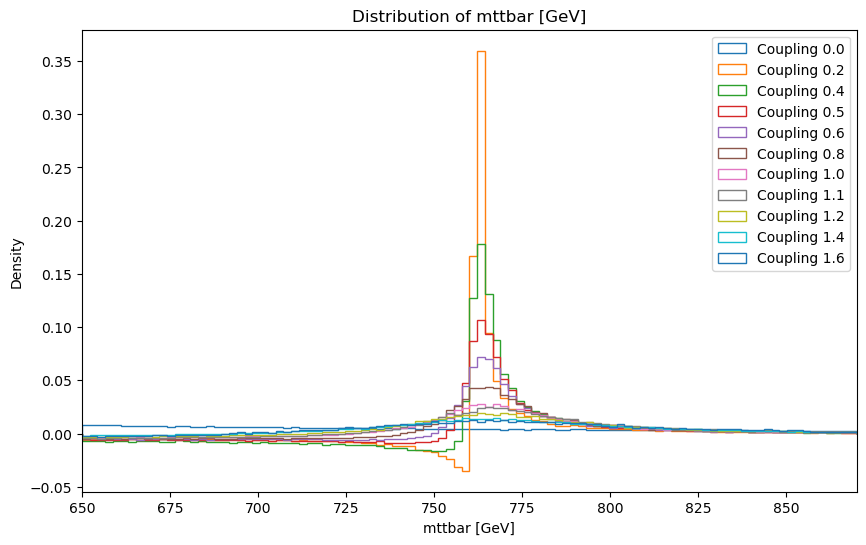

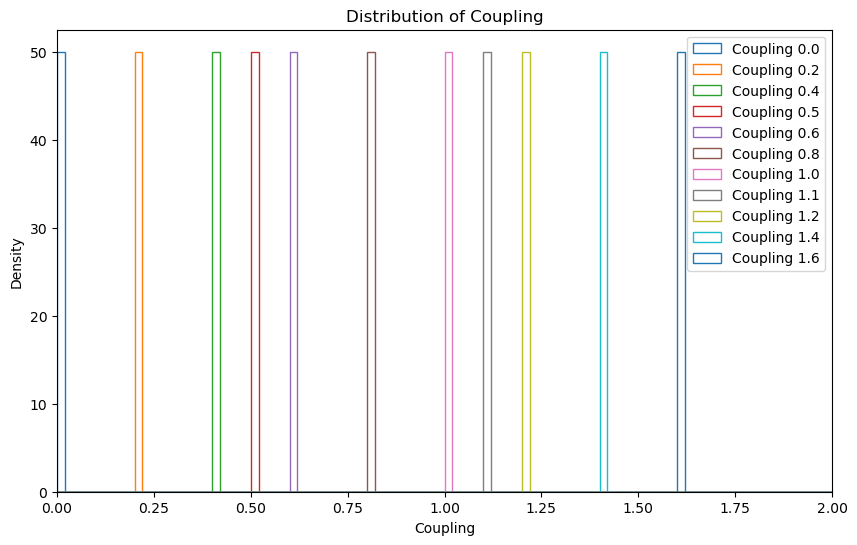

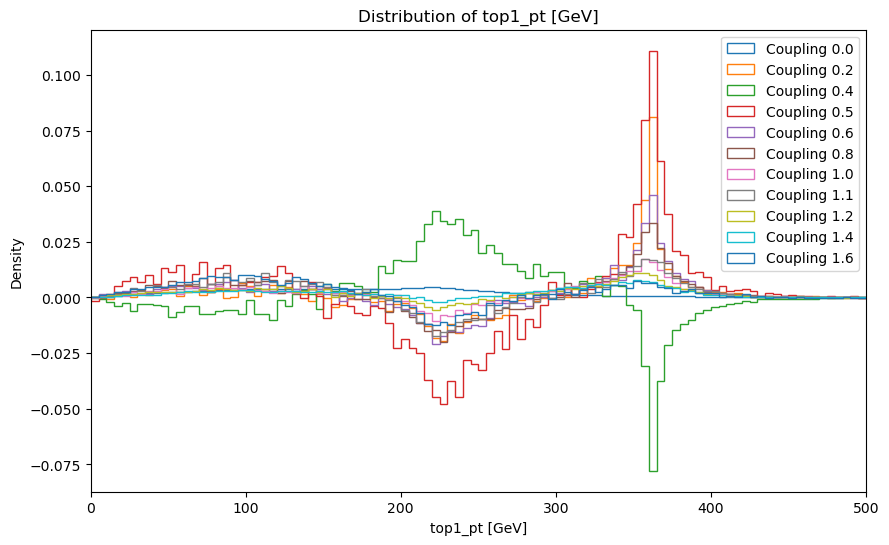

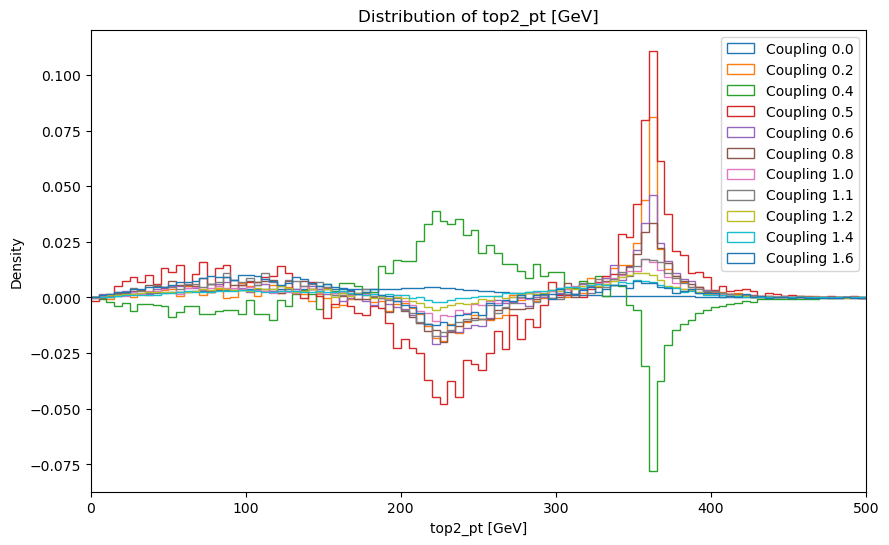

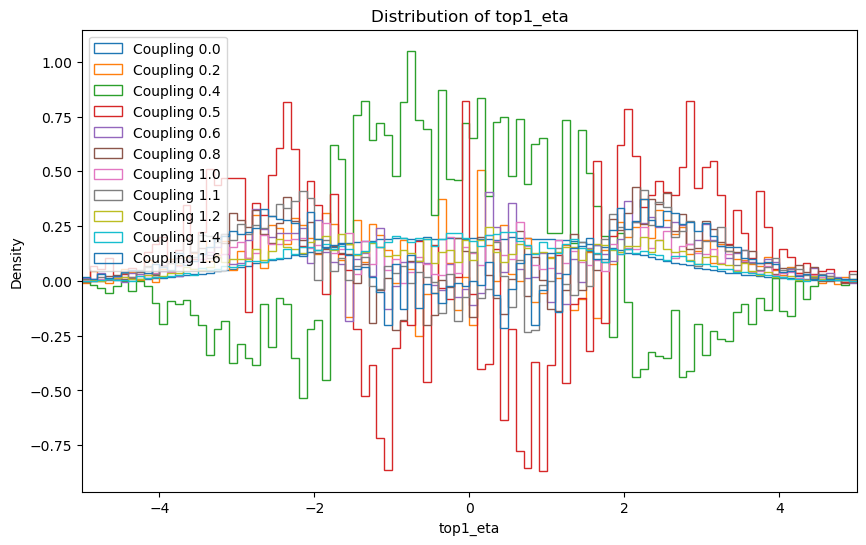

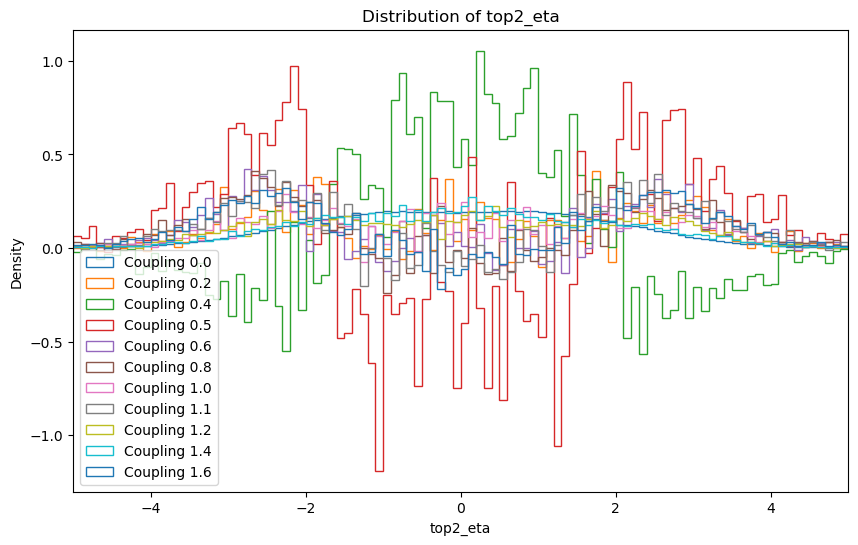

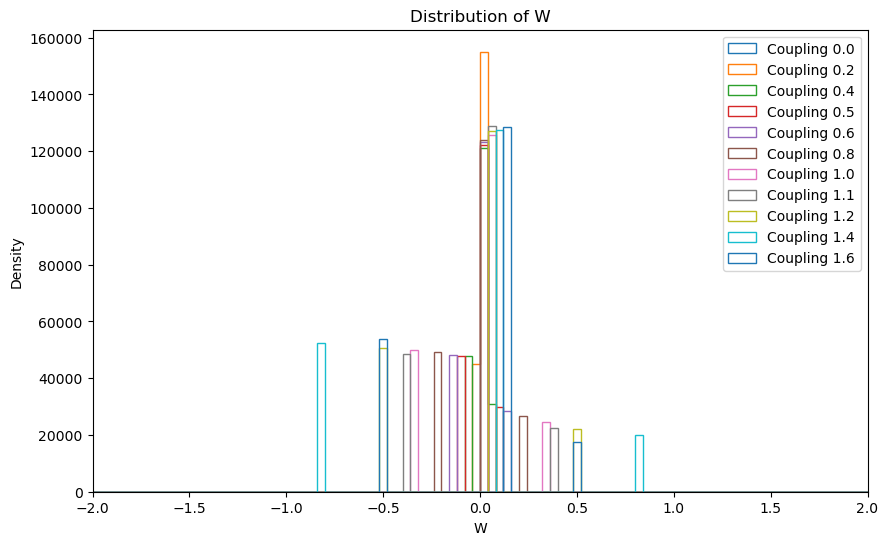

In [73]:
###### 
compare_distributions(data_file['INPUTS']['EVENT_GLOBAL']['mttbar'][:], data_file['INPUTS']['EVENT_GLOBAL']['lumiWeight'][:], indices_per_coupling, x_range=[650,870], variable_name='mttbar [GeV]', n_bins=100)
compare_distributions(data_file['INPUTS']['EVENT_GLOBAL']['coupling'][:], data_file['INPUTS']['EVENT_GLOBAL']['lumiWeight'][:], indices_per_coupling, x_range=[0,2], variable_name='Coupling', n_bins=100)
compare_distributions(data_file['INPUTS']['EVENT_PARTICLES']['top1_pt'][:], data_file['INPUTS']['EVENT_GLOBAL']['lumiWeight'][:], indices_per_coupling, x_range=[0,500], variable_name='top1_pt [GeV]', n_bins=100)
compare_distributions(data_file['INPUTS']['EVENT_PARTICLES']['top2_pt'][:], data_file['INPUTS']['EVENT_GLOBAL']['lumiWeight'][:], indices_per_coupling, x_range=[0,500], variable_name='top2_pt [GeV]', n_bins=100)
compare_distributions(data_file['INPUTS']['EVENT_PARTICLES']['top1_eta'][:], data_file['INPUTS']['EVENT_GLOBAL']['lumiWeight'][:], indices_per_coupling, x_range=[-5,5], variable_name='top1_eta', n_bins=100)
compare_distributions(data_file['INPUTS']['EVENT_PARTICLES']['top2_eta'][:], data_file['INPUTS']['EVENT_GLOBAL']['lumiWeight'][:], indices_per_coupling, x_range=[-5,5], variable_name='top2_eta', n_bins=100)
compare_distributions(data_file['INPUTS']['EVENT_GLOBAL']['lumiWeight'][:], data_file['INPUTS']['EVENT_GLOBAL']['lumiWeight'][:], indices_per_coupling, x_range=[-2,2], variable_name='W', n_bins=100)

In [74]:
def structure_data(data_file, coupling_values_for_training, training_indices) -> tuple[np.ndarray, np.ndarray, dict]:
    # Extract the features. 
    X, y = data_file['INPUTS']['EVENT_PARTICLES'][:], labels_dataset[:]
    X = rfn.structured_to_unstructured(X)
    X, y = X[training_indices], y[training_indices]
    X_mttbar = data_file['INPUTS']['EVENT_GLOBAL']['mttbar'][:][training_indices]
    X_couplings = data_file['INPUTS']['EVENT_GLOBAL']['coupling'][:][training_indices]
    X_weights = data_file['INPUTS']['EVENT_GLOBAL']['lumiWeight'][:][training_indices]
    y_category = np.empty_like(y)
    couplings_category_dict = {}
    for i in range(len(coupling_values)):
        couplings_category_dict[float(coupling_values[i])] = i


    # Now fill the category array by loopoing over the X_couplings and assigning the category based on the coupling value
    for i in range(len(X_couplings)):
        coupling_value = X_couplings[i]
        category = couplings_category_dict[round(float(coupling_value), 1)]
        y_category[i] = category
        # Also if the coupling is category 0, give it the first coupling value for training, which is 0.2, later on we will augment the data with the other couplings
        if category == 0:
            X_couplings[i] = coupling_values_for_training[0]

    # Form the data
    X = np.concatenate([X, X_mttbar.reshape(-1, 1), X_couplings.reshape(-1, 1), X_weights.reshape(-1,1)], axis=1)
    y = np.concatenate([y.reshape(-1, 1), y_category.reshape(-1, 1)], axis=1)

    return X, y, couplings_category_dict

def augment_data_for_background(X, y, coupling_values_for_training):
    # Now we want to augment the data, copying every background event giving it every possible coupling.
    background_indices = np.argwhere(y[:, 0] == 0).flatten()
    print("Augmenting data for background events. Number of background events to augment: ", len(background_indices))
    print("Number of augmentations per background event: ", len(coupling_values_for_training) - 1)
    augmented_X = []
    augmented_y = []
    for idx in background_indices:
        for coupling in coupling_values_for_training[1:]:
            new_X = X[idx].copy()
            new_X[-2] = coupling
            augmented_X.append(new_X)
            augmented_y.append(y[idx])

    X_ag = np.concatenate([X, augmented_X], axis=0)
    y_ag = np.concatenate([y, augmented_y], axis=0)

    return X_ag, y_ag

In [77]:
coupling_values_for_training = [0.2, 0.4, 0.6, 0.8, 1.0, 1.2, 1.4, 1.6]
X, y, couplings_category_dict = structure_data(data_file, coupling_values_for_training, training_indices)
print('Before augmentation:')
print('X shape = ',X.shape)
print('X example = ',X[1])
print('y shape = ',y.shape)
print('y example = ',y[1])

X_pre_transform, y = augment_data_for_background(X, y, coupling_values_for_training)
print('After augmentation:')
print('X shape = ',X.shape)
print('y shape = ',y.shape)

Before augmentation:
X shape =  (2200000, 9)
X example =  [ 2.3466739e+02  8.1430149e-01 -2.6250648e+00  2.3466739e+02
  4.5949781e-01  5.1652789e-01  5.3600854e+02  2.0000000e-01
  5.2450624e+00]
y shape =  (2200000, 2)
y example =  [0. 0.]
Augmenting data for background events. Number of background events to augment:  200000
Number of augmentations per background event:  7
After augmentation:
X shape =  (2200000, 9)
y shape =  (3600000, 2)


In [78]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

Using cuda device


In [79]:
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin

class LogScaler(BaseEstimator, TransformerMixin):
    def __init__(self, offset=1e-3, add_mask = False):
        self.offset = offset
        self.add_mask = add_mask

    def fit(self, X, y=None):
        return self  # no fitting needed

    def transform(self, X):
        log = np.log(X + self.offset)
        # Create a mask for nan values
        mask = np.isnan(log)
        if self.add_mask:
            return np.hstack([mask, log])
        return log

class PhiTransformer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        sin_phi = np.sin(X)
        cos_phi = np.cos(X)
        return np.hstack([sin_phi, cos_phi])


from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, MinMaxScaler


scaler = ColumnTransformer(
    [('pt',LogScaler(), [0,3]),
    ('eta',StandardScaler(), [1,4]),
    # ('phi', PhiTransformer(), [2,5]),
    ('mttbar', StandardScaler(), [6]),
    ('coupling', MinMaxScaler(), [7]),
    ('weights', 'passthrough', [8])
    ],
    remainder='drop'
)

X = scaler.fit_transform(X_pre_transform)
print("X shape after scaling = ", X.shape)
print("X example after scaling = ", X[1])

X shape after scaling =  (3600000, 7)
X example after scaling =  [ 5.4581733   5.4581733   0.5137567   0.28963703 -1.1776862   0.
  5.2450624 ]


# Separate the datasets for new observations

In [37]:
# Print the dictionary to help user steer the code
for key, values in couplings_category_dict.items():
    print(key, ' --> ', values)

0.0  -->  0
0.2  -->  1
0.4  -->  2
0.5  -->  3
0.6  -->  4
0.8  -->  5
1.0  -->  6
1.1  -->  7
1.2  -->  8
1.4  -->  9
1.6  -->  10


In [38]:
coupling_0p5_indices = np.argwhere(y[:,1]==3)
coupling_1p1_indices = np.argwhere(y[:,1]==7)

X_inference_1 = X[coupling_0p5_indices]
X_inference_2 = X[coupling_1p1_indices]
y_inference_1 = y[coupling_0p5_indices]
y_inference_2 = y[coupling_1p1_indices]

# Remove these indices from the dataset
X = np.delete(X, np.concatenate((coupling_0p5_indices, coupling_1p1_indices)), axis=0)
y = np.delete(y, np.concatenate((coupling_0p5_indices, coupling_1p1_indices)), axis=0)

In [39]:
# Split in train, val, test
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedShuffleSplit
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=0)
train_indices, test_indices = next(sss.split(X, y))

X_train, y_train = X[train_indices], y[train_indices]
X_temp, y_temp = X[test_indices], y[test_indices]
X_val, X_test, y_val, y_test     = train_test_split(X_temp, y_temp, test_size=0.5, shuffle=True)

print('Train set size = ', X_train.shape)
print('Validation set size = ', X_val.shape)
print('Test set size = ', X_test.shape)

Train set size =  (2560000, 7)
Validation set size =  (320000, 7)
Test set size =  (320000, 7)


In [40]:
# As tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_val_tensor   = torch.tensor(X_val, dtype=torch.float32)
X_test_tensor  = torch.tensor(X_test, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
y_val_tensor   = torch.tensor(y_val, dtype=torch.float32)
y_test_tensor  = torch.tensor(y_test, dtype=torch.float32)

In [41]:
from torch.utils.data import TensorDataset, DataLoader

def create_dataloaders(X_train_tensor, y_train_tensor, X_val_tensor, y_val_tensor, X_test_tensor, y_test_tensor, batch_size=1024, signal="positive", background="positive", weight_column_index=-1, label_column_index=0):
    # First check the signal and background types
    if signal not in ["positive", "negative"]:
        raise ValueError("Signal must be 'positive' or 'negative'")
    if background not in ["positive", "negative"]:
        raise ValueError("Background must be 'positive' or 'negative'")

    # Train dataset masks
    signal_mask = y_train_tensor[:, label_column_index] == 1
    background_mask = y_train_tensor[:, label_column_index] == 0

    if signal == "positive":
        signal_weight_mask = X_train_tensor[:, weight_column_index] >= 0
    else:
        signal_weight_mask = X_train_tensor[:, weight_column_index] < 0
    if background == "positive":
        background_weight_mask = X_train_tensor[:, weight_column_index] >= 0
    else:
        background_weight_mask = X_train_tensor[:, weight_column_index] < 0
    
    train_mask = (signal_mask & signal_weight_mask) | (background_mask & background_weight_mask)
    X_train = X_train_tensor[train_mask]
    y_train = y_train_tensor[train_mask]

    # Validation dataset masks
    signal_mask_val = y_val_tensor[:, label_column_index] == 1
    background_mask_val = y_val_tensor[:, label_column_index] == 0

    if signal == "positive":
        signal_weight_mask_val = X_val_tensor[:, weight_column_index] >= 0
    else:
        signal_weight_mask_val = X_val_tensor[:, weight_column_index] < 0
    if background == "positive":
        background_weight_mask_val = X_val_tensor[:, weight_column_index] >= 0
    else:
        background_weight_mask_val = X_val_tensor[:, weight_column_index] < 0

    val_mask = (signal_mask_val & signal_weight_mask_val) | (background_mask_val & background_weight_mask_val)
    X_val = X_val_tensor[val_mask]
    y_val = y_val_tensor[val_mask]

    # Test dataset masks
    signal_mask_test = y_test_tensor[:, label_column_index] == 1
    background_mask_test = y_test_tensor[:, label_column_index] == 0

    if signal == "positive":
        signal_weight_mask_test = X_test_tensor[:, weight_column_index] >= 0
    else:
        signal_weight_mask_test = X_test_tensor[:, weight_column_index] < 0
    if background == "positive":
        background_weight_mask_test = X_test_tensor[:, weight_column_index] >= 0
    else:
        background_weight_mask_test = X_test_tensor[:, weight_column_index] < 0

    test_mask = (signal_mask_test & signal_weight_mask_test) | (background_mask_test & background_weight_mask_test)
    X_test = X_test_tensor[test_mask]
    y_test = y_test_tensor[test_mask]


    # Form the datasets
    train_dataset = TensorDataset(X_train,
                                  y_train)
    val_dataset   = TensorDataset(X_val,
                                  y_val)
    test_dataset  = TensorDataset(X_test,
                                    y_test)

    # Create DataLoader objects for training, validation, and testing in batches
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=6, persistent_workers=True, drop_last=True)
    val_loader   = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=6, persistent_workers=True, drop_last=True)
    test_loader  = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=6)

    print("Training batches = ", len(train_loader))
    print("Validation batches = ", len(val_loader))
    print("Test batches = ", len(test_loader))
    

    return train_loader, val_loader, test_loader

In [42]:
import torch.nn as nn
# Define the Classifier
class RatioEstimator(nn.Module):
    def __init__(self, x_dim, theta_dim = 0, hidden_dim = 64):
        super(RatioEstimator, self).__init__()
        self.theta_dim = theta_dim
        if self.theta_dim == 0:
            print("NN: Using non-parametric model.")
            print("X dimension =", x_dim)
        else:
            print("NN: Using parametric model with theta dimension =", theta_dim)
            print("X dimension =", x_dim)
        self.net = nn.Sequential(
            nn.Linear(x_dim + theta_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(p=0.05),
            nn.Linear(hidden_dim, hidden_dim//2),
            nn.ReLU(),
            nn.Dropout(p=0.05),
            nn.Linear(hidden_dim//2, 1),
        )

    def forward(self, X, theta):
        model_input = torch.cat([X, theta], dim=1)
        logits = self.net(model_input)
        return logits
    
def norm_weights_per_batch(weights, categories):
    # Extract what categories are present in the batch
    unique_categories = torch.unique(categories)
    number_of_categories = len(unique_categories)
    # For each category, compute the sum of weights and normalize the weights in that category
    for category in unique_categories:
        category_mask = (categories == category)
        category_weights_sum = weights[category_mask].sum()
        if category_weights_sum > 0 and category!=0:
            weights[category_mask] = weights[category_mask] / (category_weights_sum * (number_of_categories-1))
        elif category_weights_sum > 0 and category==0:
            weights[category_mask] = weights[category_mask] / category_weights_sum
    return weights

In [43]:
# Training loop on mini-batches with loss stored for plotting
import time
def train(model, criterion, optimizer, scheduler, train_loader, val_loader, n_epochs=200, device='cpu'):
    start_time = time.time()
    train_losses = []
    val_losses = []
    
    model.to(device)
    
    for epoch in range(n_epochs):
        epoch_start_time = time.time()
        model.train()
        # run over batches of data
        running_loss = 0.0
        for inputs, targets in train_loader:
            optimizer.zero_grad()
            inputs_device = inputs.to(device)
            targets_device = targets[:,0].to(device)
            categories_device = targets[:,1].to(device)
            X = inputs_device[:,:-2]
            theta = inputs_device[:,-2].unsqueeze(1)
            outputs = model(X, theta)
            # outputs = torch.sigmoid(outputs)
            # Weight according to (1/W_1)*wi_1 + (1/W_0)*wi_0
            weights = inputs_device[:,-1]
            weights = torch.abs(weights)
            norm_weigths = norm_weights_per_batch(weights, categories_device)
            # Calculate the weighted loss
            loss = criterion(outputs.squeeze(), targets_device) * norm_weigths
            loss = torch.sum(loss)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
    
        # compute avergae loss over all batches
        train_loss = running_loss / len(train_loader)
        train_losses.append(train_loss)
    
        # Validation step
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs_device = inputs.to(device)
                targets_device = targets[:,0].to(device)
                categories_device = targets[:,1].to(device)
                X = inputs_device[:,:-2]
                theta = inputs_device[:,-2].unsqueeze(1)
                outputs = model(X, theta)
                # outputs = torch.sigmoid(outputs)
                # Weight according to (1/W_1)*wi_1 + (1/W_0)*wi_0
                weights = inputs_device[:,-1]
                weights = torch.abs(weights)
                norm_weigths = norm_weights_per_batch(weights, categories_device)
                # Calculate the weighted loss
                loss = criterion(outputs.squeeze(), targets_device) * norm_weigths
                loss = torch.sum(loss)
                val_loss += loss.item()
    
        val_loss /= len(val_loader)
        val_losses.append(val_loss)
        scheduler.step(val_loss)

        current_time = time.time()
        print(f"Total Time: {round(current_time - start_time,1)}s, Epoch Time: {round(current_time - epoch_start_time,2)}s")
        print(f"Learning rate: {scheduler.get_last_lr()[0]}")
        print(f"Epoch {epoch+1}/{n_epochs}, Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}")

    # Plot loss function for training and validation sets
    plt.plot(train_losses, label='Train Loss', color='red')
    plt.plot(val_losses, label='Validation Loss', color='green')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(['Train Loss', 'Validation Loss'])
    plt.show()

In [44]:
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau
model_pp = RatioEstimator(x_dim = 5, theta_dim = 1, hidden_dim = 64)
criterion = nn.BCEWithLogitsLoss(reduction='none')
optimizer_pp = optim.AdamW(model_pp.parameters(), lr=0.0002, weight_decay=1e-3)
scheduler_pp = ReduceLROnPlateau(optimizer_pp, "min", patience=10, factor=0.8)

train_loader_pp, val_loader_pp, test_loader_pp = create_dataloaders(X_train_tensor, y_train_tensor,
                                                                X_val_tensor, y_val_tensor,
                                                                X_test_tensor, y_test_tensor,
                                                                batch_size=2048,
                                                                signal="positive",
                                                                background="positive")

NN: Using parametric model with theta dimension = 1
X dimension = 5
Training batches =  1094
Validation batches =  136
Test batches =  137


Total Time: 6.2s, Epoch Time: 6.16s
Learning rate: 0.0002
Epoch 1/150, Train Loss: 1.2118, Val Loss: 1.1533
Total Time: 13.2s, Epoch Time: 7.08s
Learning rate: 0.0002
Epoch 2/150, Train Loss: 1.1490, Val Loss: 1.1396
Total Time: 20.5s, Epoch Time: 7.24s
Learning rate: 0.0002
Epoch 3/150, Train Loss: 1.1395, Val Loss: 1.1344
Total Time: 26.8s, Epoch Time: 6.29s
Learning rate: 0.0002
Epoch 4/150, Train Loss: 1.1361, Val Loss: 1.1319
Total Time: 33.2s, Epoch Time: 6.43s
Learning rate: 0.0002
Epoch 5/150, Train Loss: 1.1338, Val Loss: 1.1297
Total Time: 40.1s, Epoch Time: 6.91s
Learning rate: 0.0002
Epoch 6/150, Train Loss: 1.1323, Val Loss: 1.1287
Total Time: 47.2s, Epoch Time: 7.13s
Learning rate: 0.0002
Epoch 7/150, Train Loss: 1.1311, Val Loss: 1.1276
Total Time: 53.4s, Epoch Time: 6.16s
Learning rate: 0.0002
Epoch 8/150, Train Loss: 1.1301, Val Loss: 1.1271
Total Time: 60.2s, Epoch Time: 6.81s
Learning rate: 0.0002
Epoch 9/150, Train Loss: 1.1293, Val Loss: 1.1262
Total Time: 67.1s, E

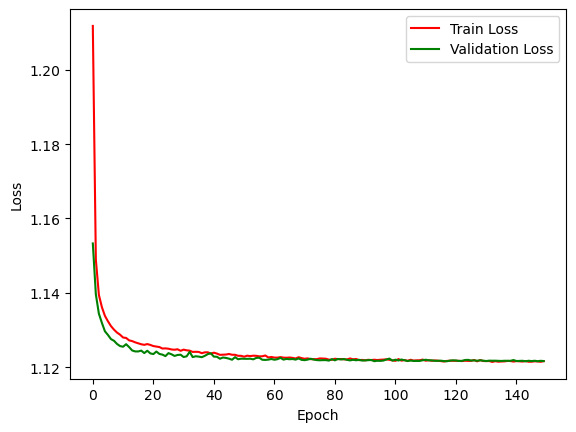

In [45]:
# Train pp model
train(model_pp, criterion, optimizer_pp, scheduler_pp, train_loader_pp, val_loader_pp, n_epochs=150, device=device)

In [49]:
def save_model(model, model_name, skip_confirmation = False):
    import os
    save_model = False
    if skip_confirmation:
        save_model = True
    else:
        save_model = input("Do you want to save the model? [y/n]") == "y"

    if not save_model:
        print("Model not saved")
        return
        
    if model_name in os.listdir():
        overwrite = input("Model already in the directory. Overwrite? [y/n]") =="y"
        if not overwrite:
            print("Model not saved")
            return
    
    print("Saving model...")
    torch.save(model.state_dict(), model_name)


save_model(model_pp, 'Coupling_Inference_SI_vs_BG_PP.pth', skip_confirmation = True)

Model already in the directory. Overwrite? [y/n] y


Saving model...


NN: Using parametric model with theta dimension = 1
X dimension = 5


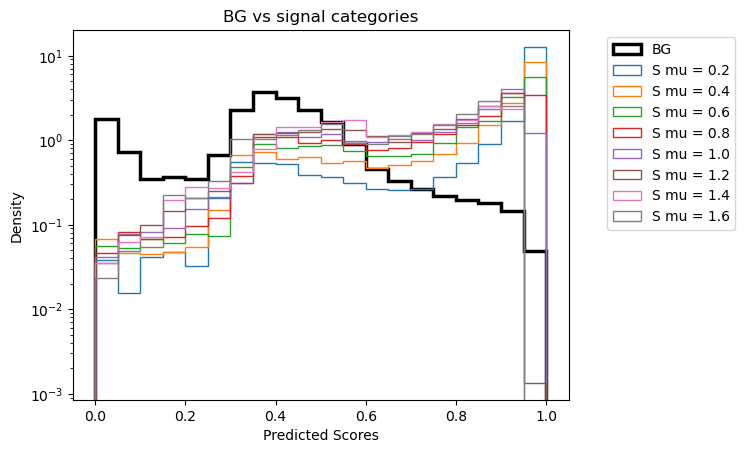

In [50]:
load_model = True
if load_model:
    eval_model = RatioEstimator(x_dim = 5, theta_dim = 1, hidden_dim = 64)
    eval_model.load_state_dict(torch.load('Coupling_Inference_SI_vs_BG_PP.pth', weights_only=True))
    model_pp = eval_model
else:
    eval_model = model_pp


eval_model.to('cpu')
eval_model.eval()

X_test_cpu = test_loader_pp.dataset.tensors[0].to('cpu')
y_test_cpu = test_loader_pp.dataset.tensors[1].to('cpu')

y_pred = torch.sigmoid(eval_model(X_test_cpu[:,:-2],X_test_cpu[:,-2].unsqueeze(1)).detach())

# Filter the predicted events for true Signal and true Background
sb_label = y_test_cpu[:,0]
category_label = y_test_cpu[:,1]
true_bkg = y_pred[sb_label==0].numpy()
training_categories = np.unique(category_label[sb_label==1])
training_categories = [int(cat) for cat in training_categories]

plt.hist(true_bkg, bins=20, histtype='step', label='Background', density=True, color='black', linewidth=2.5, range=[0,1])
plt.xlabel("Predicted Scores")
plt.ylabel("Density")
plt.title("BG vs signal categories")
#plt.xlim((0.7,0.9))
plt.yscale('log')
signal_legends = []
for icat in training_categories:
    # Plot the predicted scores for both true Signal and true Background events
    true_signal = y_pred[category_label==icat].numpy()
    plt.hist(true_signal, bins=20, histtype='step', label='Signal', density=True, range=[0,1])
    signal_legends.append(f"S mu = %s" % str(round(coupling_values[icat],2)))

plt.legend(["BG"]+signal_legends,bbox_to_anchor=(1.35, 1), loc='upper right')
plt.show()

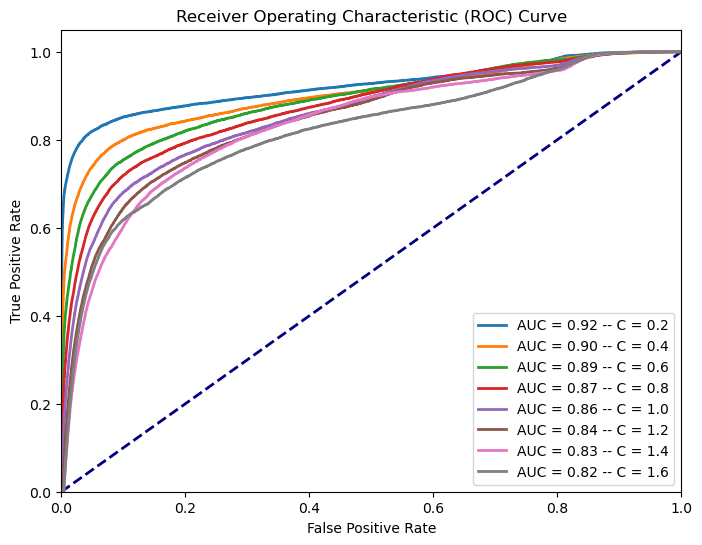

In [51]:
# Compute ROC curve
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(8, 6))
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')  # Random classifier line
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')

for icat in training_categories:
    y_pred_cat = y_pred[(category_label==icat) | (category_label==0)].numpy()
    y_test_cat = y_test_cpu[(category_label==icat) | (category_label==0)]
    fpr, tpr, thresholds = roc_curve(y_test_cat[:,0], y_pred_cat)
    # Compute AUC (Area Under Curve)
    roc_auc = auc(fpr, tpr)
    # Plot ROC curve
    plt.plot(fpr, tpr, lw=2, label=f'AUC = {roc_auc:.2f} -- C = {round(coupling_values[icat],2)}')
    
plt.legend(loc='lower right')
plt.show()

In [21]:
model_pn = RatioEstimator(x_dim = 5, theta_dim = 1, hidden_dim = 64)
criterion = nn.BCEWithLogitsLoss(reduction='none')
optimizer_pn = optim.AdamW(model_pn.parameters(), lr=0.0002, weight_decay=1e-3)
scheduler_pn = ReduceLROnPlateau(optimizer_pn, "min", patience=10, factor=0.8)

train_loader_pn, val_loader_pn, test_loader_pn = create_dataloaders(X_train_tensor, y_train_tensor,
                                                                X_val_tensor, y_val_tensor,
                                                                X_test_tensor, y_test_tensor,
                                                                batch_size=2048,
                                                                signal="negative",
                                                                background="positive")

NN: Using parametric model with theta dimension = 1
X dimension = 5
Training batches =  780
Validation batches =  97
Test batches =  98


Total Time: 5.7s, Epoch Time: 5.74s
Learning rate: 0.0002
Epoch 1/200, Train Loss: 0.8250, Val Loss: 0.6639
Total Time: 9.7s, Epoch Time: 3.91s
Learning rate: 0.0002
Epoch 2/200, Train Loss: 0.6542, Val Loss: 0.6291
Total Time: 14.3s, Epoch Time: 4.63s
Learning rate: 0.0002
Epoch 3/200, Train Loss: 0.6346, Val Loss: 0.6168
Total Time: 17.9s, Epoch Time: 3.65s
Learning rate: 0.0002
Epoch 4/200, Train Loss: 0.6243, Val Loss: 0.6101
Total Time: 21.7s, Epoch Time: 3.77s
Learning rate: 0.0002
Epoch 5/200, Train Loss: 0.6189, Val Loss: 0.6064
Total Time: 26.2s, Epoch Time: 4.5s
Learning rate: 0.0002
Epoch 6/200, Train Loss: 0.6148, Val Loss: 0.6049
Total Time: 30.2s, Epoch Time: 3.98s
Learning rate: 0.0002
Epoch 7/200, Train Loss: 0.6114, Val Loss: 0.6014
Total Time: 34.3s, Epoch Time: 4.1s
Learning rate: 0.0002
Epoch 8/200, Train Loss: 0.6089, Val Loss: 0.6003
Total Time: 38.5s, Epoch Time: 4.18s
Learning rate: 0.0002
Epoch 9/200, Train Loss: 0.6076, Val Loss: 0.5989
Total Time: 42.2s, Epoc

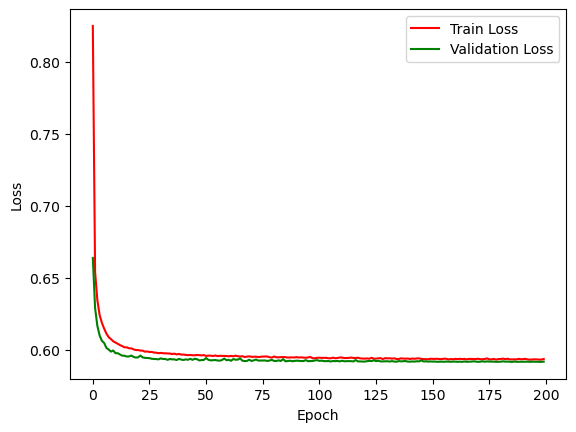

In [22]:
train(model_pn, criterion, optimizer_pn, scheduler_pn, train_loader_pn, val_loader_pn, n_epochs=200, device=device)

In [23]:
save_model(model_pp, 'Coupling_Inference_SI_vs_BG_PN.pth', skip_confirmation = True)

Saving model...


NN: Using parametric model with theta dimension = 1
X dimension = 5
Doing category = 1
Doing category = 2
Doing category = 4
Doing category = 5
Doing category = 6
Doing category = 8
Doing category = 9
Doing category = 10


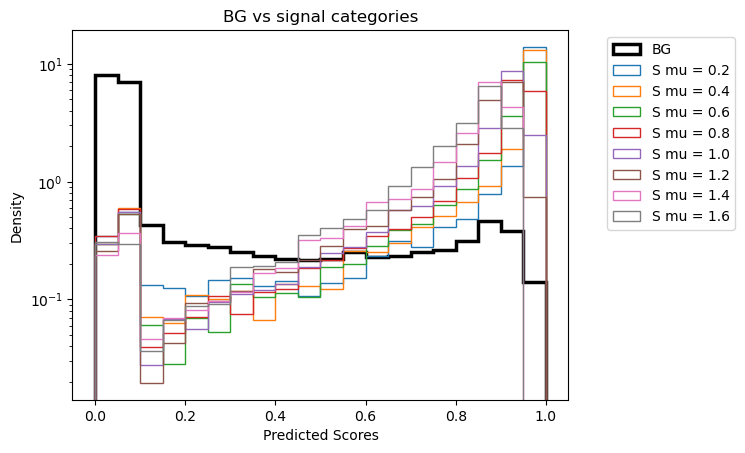

In [52]:
load_model = True
if load_model:
    eval_model = RatioEstimator(x_dim = 5, theta_dim = 1, hidden_dim = 64)
    eval_model.load_state_dict(torch.load('Coupling_Inference_SI_vs_BG_PN.pth', weights_only=True))
    model_pn = eval_model
else:
    eval_model = model_pn


eval_model.to('cpu')
eval_model.eval()

X_test_cpu = test_loader_pn.dataset.tensors[0].to('cpu')
y_test_cpu = test_loader_pn.dataset.tensors[1].to('cpu')

y_pred = torch.sigmoid(eval_model(X_test_cpu[:,:-2],X_test_cpu[:,-2].unsqueeze(1)).detach())

# Filter the predicted events for true Signal and true Background
sb_label = y_test_cpu[:,0]
category_label = y_test_cpu[:,1]
true_bkg = y_pred[sb_label==0].numpy()
training_categories = np.unique(category_label[sb_label==1])
training_categories = [int(cat) for cat in training_categories]

plt.hist(true_bkg, bins=20, histtype='step', label='Background', density=True, color='black', linewidth=2.5, range=[0,1])
plt.xlabel("Predicted Scores")
plt.ylabel("Density")
plt.title("BG vs signal categories")
#plt.xlim((0.7,0.9))
plt.yscale('log')
signal_legends = []
for icat in training_categories:
    # Plot the predicted scores for both true Signal and true Background events
    print(f"Doing category = {icat}")
    true_signal = y_pred[category_label==icat].numpy()
    plt.hist(true_signal, bins=20, histtype='step', label='Signal', density=True, range=[0,1])
    signal_legends.append(f"S mu = %s" % str(round(coupling_values[icat],2)))

plt.legend(["BG"]+signal_legends,bbox_to_anchor=(1.35, 1), loc='upper right')
plt.show()

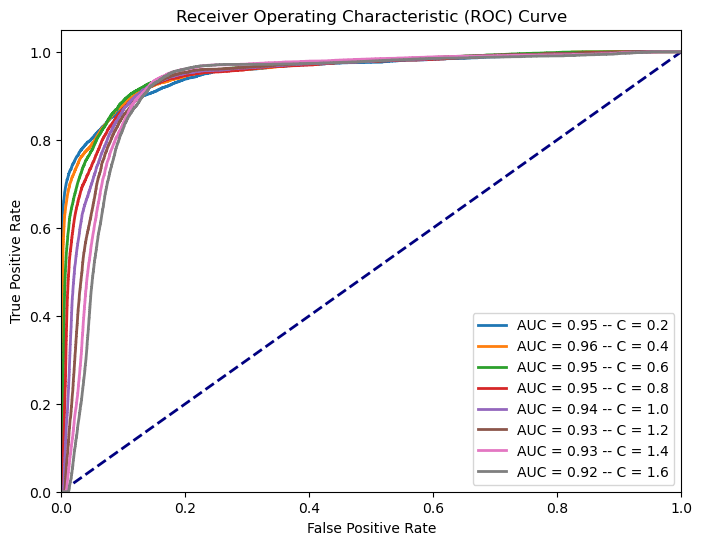

In [53]:
# Compute ROC curve
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(8, 6))
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')  # Random classifier line
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')

for icat in training_categories:
    y_pred_cat = y_pred[(category_label==icat) | (category_label==0)].numpy()
    y_test_cat = y_test_cpu[(category_label==icat) | (category_label==0)]
    fpr, tpr, thresholds = roc_curve(y_test_cat[:,0], y_pred_cat)
    # Compute AUC (Area Under Curve)
    roc_auc = auc(fpr, tpr)
    # Plot ROC curve
    plt.plot(fpr, tpr, lw=2, label=f'AUC = {roc_auc:.2f} -- C = {round(coupling_values[icat],2)}')
    
plt.legend(loc='lower right')
plt.show()

In [54]:
# Calculate the mixture coefficcients

# C(y) = Sum(wi for wi >0) / Sum(wi) with wi belonging to the "y" category

# First C0 -> This is one because the BG weights are all positive
bg_mask = y_train[:,0]==0
signal_mask = y_train[:,0]==1
C_zero = (X_train[bg_mask & (X_train[:,-1]>=0)][:,-1]).sum()/ X_train[bg_mask][:,-1].sum() 
print("C0 =", C_zero)

# Now C1
C_one = (X_train[signal_mask & (X_train[:,-1]>=0)][:,-1]).sum()/ (X_train[signal_mask][:,-1]).sum()
print("C1 =", C_one)

C0 = 1.0
C1 = -4.3190293


(1600000, 9)


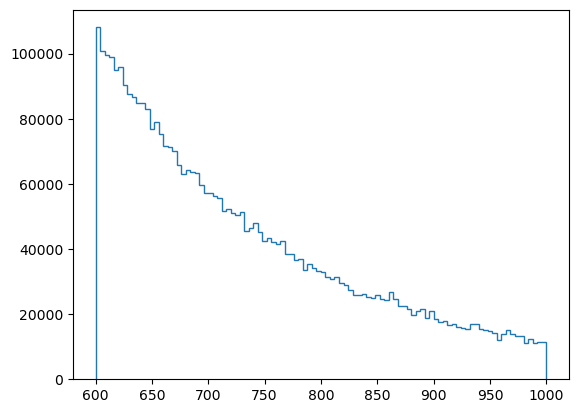

In [102]:
def Logits(x_obs, theta, eval_model):
    logits = eval_model(x_obs, theta)
    logits = logits.reshape(-1)
    return logits

def likelihood_ratio(theta, X_obs, eval_model):
    thetas = theta.unsqueeze(0).expand(len(X_obs), -1)
    logits = Logits(X_obs, thetas, eval_model)
    scores = torch.sigmoid(logits)
    llh_ratio = scores / (1-scores)
    return llh_ratio

def RoSMM(theta_tensor, X_obs, weights, model_pp, model_pn, C_zero, C_one):
    llr_pp = likelihood_ratio(theta_tensor, X_obs, model_pp)
    llr_pn = likelihood_ratio(theta_tensor, X_obs, model_pn)
    rosmm = llr_pp * C_one/C_zero + llr_pn * (1-C_one)/C_zero
    return rosmm

# THIS IS NOT USEFUL 
'''
def log_likelihood_ratio(theta_tensor, X_obs, weights, model_pp, model_pn, C_zero, C_one):
    llh_ratio = RoSMM(theta_tensor, X_obs, weights, model_pp, model_pn, C_zero, C_one)
    log_llh_ratio =torch.log(llh_ratio*llh_rat)
    return torch.sum(weights*log_llh_ratio)

def parameter_inference(theta_scan, X_obs, weights, model_pp, model_pn, C_zero, C_one):
    log_likelihoods = []
    
    for itheta in theta_scan:
        theta_transformed = scaler["coupling"].transform([[itheta]])[0,0]
        print("Scanning theta = ", round(theta_transformed, 2))
        theta_tensor = torch.tensor([theta_transformed], requires_grad=False, dtype=torch.float32)
        # llh = corrected_log_likelihood(theta_tensor, new_X, weights, X_ref, weights_ref)
        llh = log_likelihood_ratio(theta_tensor, X_obs, weights, model_pp, model_pn, C_zero, C_one)
        log_likelihoods.append(llh.item())

    max_llh = np.array(max(log_likelihoods))
    q_mu = -2*(log_likelihoods - max_llh)
    q_mu = log_likelihoods

    plt.plot(theta_scan, q_mu)
    plt.xlabel("Theta")
    plt.ylabel("q_mu")
    plt.xlim((min(theta_scan),max(theta_scan)))
    plt.show()

    # Get the MLE estimate for theta
    np.argmin(q_mu)
    theta_mle = theta_scan[np.argmin(q_mu)]
    print("MLE estimate for theta:", theta_mle)

    return theta_mle, q_mu

new_data =  X_inference_2
new_data = new_data.reshape(-1, new_data.shape[2])
weights = torch.tensor(new_data[:,-1], requires_grad=False, dtype=torch.float32)
new_data = new_data[:,:-2] # Remove weight and coupling column
new_X = torch.tensor(new_data, requires_grad=False, dtype=torch.float32)

theta_scan = np.linspace(0.1,1.5,50)
theta_mle, q_mu = parameter_inference(theta_scan, new_X, weights, model_pp, model_pn, C_zero, C_one)
'''

bg_mask = y[:,0] == 0
sig_mask = coupling_0p5_indices
bg_data =  X_pre_transform[bg_mask].reshape(-1,X_pre_transform.shape[1])
print(new_data.shape)
bg_weights = bg_data[:,-1]
bg_mttbar = bg_data[:,-3]
plt.hist(bg_mttbar, weights=weights, bins=100, histtype='step', label=f'Coupling {coupling}', density=False, range=[600,1000])


plt.show()


# def ratio(x_obs, theta, model):
    model.to('cpu')
    X = torch.cat([x_obs, theta], dim=1)
    logits = model(X)
    s = torch.sigmoid(logits)
    r = s / (1 - s)
    return r

def log_likelihood(theta, X_obs, model_pp, model_pn, c0, c1, MC_weights):
    # X_obs: shape [N, x_dim]
    theta_transformed = scaler["coupling"].transform([[theta]])[0,0]
    delta_theta = 0.2
    theta_p_transformed = scaler["coupling"].transform([[theta + delta_theta]])[0,0]
    theta_n_transformed = scaler["coupling"].transform([[theta - delta_theta]])[0,0]

    # Transform to tensors
    theta_tensor = torch.tensor(theta_transformed, requires_grad=False, dtype=torch.float32)
    theta_p_tensor = torch.tensor(theta_p_transformed, requires_grad=False, dtype=torch.float32)
    theta_n_tensor = torch.tensor(theta_n_transformed, requires_grad=False, dtype=torch.float32)
    
    # Transform into vectors
    thetas = theta_tensor.unsqueeze(0).expand(len(X_obs), -1)
    thetas_p = theta_p_tensor.unsqueeze(0).expand(len(X_obs), -1)
    thetas_n = theta_n_tensor.unsqueeze(0).expand(len(X_obs), -1)
    
    # Neutral
    r_pp = ratio(X_obs, thetas, model_pp)
    r_pn = ratio(X_obs, thetas, model_pn)
    r_vals = r_pp * c1/c0 + r_pn * (1-c1)/c0
    r_vals = r_vals.reshape(-1)
    sign = r_vals/torch.abs(r_vals)*MC_weights
    # Positive
    r_pp_p = ratio(X_obs, thetas_p, model_pp)
    r_pn_p = ratio(X_obs, thetas_p, model_pn)
    r_vals_p = r_pp_p * c1/c0 + r_pn_p * (1-c1)/c0
    r_vals_p = r_vals_p.reshape(-1)
    # Negative
    r_pp_n = ratio(X_obs, thetas_n, model_pp)
    r_pn_n = ratio(X_obs, thetas_n, model_pn)
    r_vals_n = r_pp_n * c1/c0 + r_pn_n * (1-c1)/c0
    r_vals_n = r_vals_n.reshape(-1)

    s_p = torch.log(torch.abs(r_vals_p)+0.0000001)
    s_n = torch.log(torch.abs(r_vals_n)+0.0000001)

    s = (s_p - s_n)/2*delta_theta
    
    return (torch.dot(s,sign))**2


def scan_likelihood(new_data, x_scan, model_pp, model_pn, C_zero, C_one):
    new_data = new_data.reshape(-1, new_data.shape[2])
    new_data = new_data[:,:-2] # Remove coupling and weeightcolumn
    MC_weights = torch.tensor(new_data[:,-1], requires_grad=False)
    new_X = torch.tensor(new_data, requires_grad=False)
    
    log_likelihoods = []
    for ix in x_scan:
        llh = log_likelihood(ix, new_X, model_pp, model_pn, C_zero, C_one, MC_weights) # Evaluate using the ML model!
        log_likelihoods.append(llh.item())

    return log_likelihoods